# ❤️ Proyecto: Predicción de Enfermedades Cardiovasculares

## 🎯 Objetivos del Proyecto

En este proyecto práctico aprenderás a:

1. **Trabajar con datos médicos reales** del UCI Heart Disease Dataset
2. **Construir un pipeline completo** de Machine Learning
3. **Evaluar modelos de clasificación binaria** con múltiples métricas
4. **Comparar diferentes algoritmos** (SGD vs Random Forest)
5. **Registrar experimentos** con MLflow de forma profesional
6. **Interpretar resultados médicos** con responsabilidad

---

## ❤️ ¿Por qué es importante?

Las **Enfermedades Cardiovasculares (ECV)** son la principal causa de muerte en el mundo:

- 💔 Causan **17.9 millones** de muertes al año
- ⚠️ **90% son prevenibles** con detección temprana
- 🏥 Un diagnóstico temprano puede **salvar vidas**
- 🤖 La IA puede ayudar a **detectar patrones** que salven vidas

---

## 📊 El Dataset: UCI Heart Disease

- **303 pacientes** con datos clínicos
- **14 características** médicas (edad, presión arterial, colesterol, etc.)
- **Variable objetivo**: Presencia de enfermedad cardíaca (0/1)
- **Tipo de problema**: Clasificación binaria

---

## 🎓 Ejercicio Especial: Completa los Comentarios

**🚨 IMPORTANTE**: A lo largo de este notebook verás comentarios como:

```python
# TODO: [Completa aquí] ¿Qué hace esta función?
```

**Tu misión** es completar estos comentarios explicando:
- ¿Qué hace el código?
- ¿Por qué es importante?
- ¿Qué resultado esperamos?

Esto te ayudará a:
- ✅ Entender profundamente cada paso
- ✅ Practicar documentación de código
- ✅ Prepararte para proyectos reales

---

## 🚀 ¡Empecemos!

## ⚙️ Paso 2: Configuración de MLflow

Configuramos el experimento donde registraremos todos nuestros entrenamientos.

## 📚 Paso 3: Importar Librerías

Importamos todas las herramientas necesarias para el proyecto.

In [0]:
import mlflow
import warnings
warnings.filterwarnings('ignore')

mlflow.set_tracking_uri("databricks")
mlflow.set_registry_uri("databricks")

# TODO: Debo sustituir este correo por la dirección de correo electrónico con la que tengo iniciada mi sesión en Databricks. Esto permite que el experimento se guarde dentro de mi carpeta personal (/Users/<mi-correo>/...) y no interfiera con los experimentos de otros compañeros ¿Qué debes hacer con esta variable email?
email = 'pedroperezdiaz1@gmail.com'  # ⚠️ CAMBIAR POR TU EMAIL DE DATABRICKS

# Validación
if not email:
    print("⚠️  ADVERTENCIA: Debes configurar tu email antes de continuar")
else:
    # TODO: [Sirve para configurar el servidor de seguimiento (Tracking Server) de MLflow. Al pasarle "databricks", le indicamos que registre todos los parámetros, métricas y artefactos directamente en el workspace de Databricks en lugar de en el disco local.] ¿Para qué sirve set_tracking_uri?
    mlflow.set_tracking_uri("databricks")
    
    # TODO: [Establece el nombre y la ruta del experimento activo en MLflow. Si el experimento no existe en Databricks, lo crea automáticamente; si ya existe, lo selecciona para que todas las ejecuciones (runs) y modelos entrenados se guarden organizados en ese mismo lugar.í] ¿Qué hace set_experiment?
    experiment_name = f"/Users/{email}/5-prediccion-infarto"
    mlflow.set_experiment(experiment_name)
    
    print("=" * 70)
    print("✅ MLflow configurado correctamente")
    print("=" * 70)
    print(f"📊 Experimento: {experiment_name}")
    print(f"❤️  Proyecto: Predicción de Enfermedades Cardiovasculares")
    print("=" * 70)

✅ MLflow configurado correctamente
📊 Experimento: /Users/pedroperezdiaz1@gmail.com/5-prediccion-infarto
❤️  Proyecto: Predicción de Enfermedades Cardiovasculares


In [0]:
# Librerías básicas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# TODO: [Sirve para dividir el conjunto de datos en dos particiones independientes: entrenamiento (train) y prueba (test). Es fundamental para evaluar la capacidad de generalización del modelo frente a datos nunca antes vistos y prevenir la fuga de datos (data leakage)] ¿Para qué sirve train_test_split?
from sklearn.model_selection import train_test_split

# TODO: [Un Pipeline es una estructura que encadena de forma secuencial múltiples pasos de preprocesamiento y modelado en un único objeto. Garantiza reproducibilidad, evita fugas de información entre entrenamiento y prueba, y facilita el empaquetado del modelo para su despliegue en producción] ¿Qué es un Pipeline en sklearn?
from sklearn.pipeline import Pipeline

# Preprocesamiento
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

# TODO: [Usaremos SGDClassifier como modelo base (baseline) lineal ligero y rápido, y RandomForestClassifier como modelo de ensamble no lineal más complejo. Esto permite comparar un algoritmo simple frente a uno avanzado para analizar el balance entre precisión, interpretabilidad y coste computacional.] ¿Qué modelos vamos a usar?
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier

# TODO: [Sirve para realizar validación cruzada (K-fold cross-validation). Evalúa el rendimiento del modelo dividiendo los datos en varios subconjuntos iterativos para obtener una estimación robusta, evitando que la métrica dependa de una partición afortunada o sesgada de los datos.] ¿Para qué sirve cross_val_score?
from sklearn.model_selection import cross_val_score, cross_val_predict

# TODO: [Usaremos Accuracy, Precision, Recall, F1-Score y ROC-AUC. En un problema médico de detección de infartos, la métrica crítica es el Recall (Sensibilidad), ya que el coste de un Falso Negativo (no detectar a un paciente enfermo) puede ser mortal, priorizándolo sobre el coste de un Falso Positivo.] ¿Qué métricas usaremos y por qué?
from sklearn.metrics import (
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix, 
    ConfusionMatrixDisplay, 
    roc_auc_score,
    accuracy_score,
    classification_report,
    roc_curve
)

# Configuración de visualización
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")

print("✅ Todas las librerías importadas correctamente")

✅ Todas las librerías importadas correctamente


## ❤️ Contexto del Proyecto

### El Problema

En este proyecto trabajaremos con el **UCI Heart Disease Dataset**, uno de los datasets más importantes en medicina predictiva. 

### 📊 Datos Clave sobre ECV

- 💔 **Principal causa de muerte** a nivel mundial
- 📈 **17.9 millones** de muertes anuales
- ⚠️ **90% son prevenibles** con detección temprana
- 🎯 **Diagnóstico temprano** = vidas salvadas
- 🤖 **IA** puede detectar patrones imperceptibles para humanos

### 🎯 Nuestro Objetivo

Construir un modelo de Machine Learning que pueda **predecir la presencia de enfermedad cardiovascular** basándose en características clínicas del paciente.

### ⚕️ Responsabilidad Ética

> ⚠️ **IMPORTANTE**: Este es un proyecto educativo. Los modelos médicos reales requieren:
> - Validación clínica exhaustiva
> - Aprobación regulatoria
> - Supervisión médica profesional
> - Consideraciones éticas y legales

Nuestro objetivo es aprender las técnicas, no reemplazar el criterio médico.

## 📚 Fundamentos: Clasificación Binaria

### 🎯 ¿Qué es Clasificación Binaria?

Un problema donde el modelo debe elegir entre **dos clases**:
- ✅ Clase Positiva (1): Tiene enfermedad cardíaca
- ❌ Clase Negativa (0): No tiene enfermedad cardíaca

---

### 🔄 Pipeline de Entrenamiento

```
1. Preparación de Datos
   ↓
2. Selección del Modelo
   ↓
3. Entrenamiento
   ↓
4. Ajuste de Hiperparámetros
   ↓
5. Evaluación
```

---

### 📊 Métricas de Evaluación

#### 1. **Matriz de Confusión**

|                    | Predicción: No (0) | Predicción: Sí (1) |
|--------------------|--------------------|--------------------|
| **Real: No (0)**   | TN (Verdadero Neg) | FP (Falso Positivo)|
| **Real: Sí (1)**   | FN (Falso Negativo)| TP (Verdadero Pos) |

#### 2. **Precision (Precisión)**
```
Precision = TP / (TP + FP)
```
- "De los que predije como enfermos, ¿cuántos realmente lo están?"
- **Importante cuando**: Los falsos positivos son costosos

#### 3. **Recall (Sensibilidad)**
```
Recall = TP / (TP + FN)
```
- "De todos los enfermos reales, ¿cuántos detecté?"
- **Importante cuando**: No podemos perder ningún caso positivo (medicina)

#### 4. **F1-Score**
```
F1 = 2 × (Precision × Recall) / (Precision + Recall)
```
- Balance entre Precision y Recall
- Útil cuando las clases están desbalanceadas

#### 5. **ROC-AUC**
- Curva ROC: Representa el trade-off entre True Positive Rate y False Positive Rate
- AUC: Área bajo la curva (0.5 = aleatorio, 1.0 = perfecto)

#### 6. **Validación Cruzada**
- Divide datos en K partes (folds)
- Entrena K veces, cada vez con un fold diferente como test
- Promedia resultados para obtener estimación robusta

---

### 🎯 ¿Qué métrica usar?

| Situación | Métrica Principal |
|-----------|-------------------|
| Clases balanceadas | Accuracy |
| No perder positivos (medicina) | **Recall** ⭐ |
| Evitar falsos positivos | Precision |
| Balance general | F1-Score |
| Comparar modelos | ROC-AUC |

**En medicina, típicamente priorizamos Recall** porque es mejor detectar un caso falso positivo que perder un verdadero positivo.

## 📁 Paso 4: Cargar y Explorar los Datos

Cargamos el dataset y realizamos un análisis exploratorio inicial.

In [0]:
# TODO: [Los datos se cargan desde una ruta local relativa (../data/raw/heart.csv), correspondiente al UCI Heart Disease Dataset. El archivo contiene registros clínicos de 303 pacientes con 13 características médicas (edad, presión arterial, colesterol, dolor torácico, etc.) y una columna objetivo (target) que indica la presencia (1) o ausencia (0) de patología cardiovascular] ¿De dónde cargamos los datos y qué contiene este archivo?
data = pd.read_csv('../data/raw/heart.csv')

print("=" * 70)
print("❤️  DATASET CARGADO: UCI HEART DISEASE")
print("=" * 70)
print(f"📊 Número de muestras: {len(data)}")
print(f"📈 Número de características: {len(data.columns) - 1}")  # -1 porque target no es característica
print(f"🎯 Variable objetivo: target (0 = No enfermedad, 1 = Enfermedad)")
print("=" * 70)

❤️  DATASET CARGADO: UCI HEART DISEASE
📊 Número de muestras: 303
📈 Número de características: 13
🎯 Variable objetivo: target (0 = No enfermedad, 1 = Enfermedad)


In [0]:
# TODO: [La función head() muestra por defecto las primeras 5 filas del DataFrame. Es útil en la fase exploratoria para comprobar de inmediato que la carga fue correcta, examinar los tipos de datos preliminares, verificar la correspondencia de las columnas y detectar posibles anomalías visibles (como valores nulos NaN o mezclas de variables categóricas y numéricas).] ¿Qué nos muestra head() y por qué es útil?
print("🔍 Primeras 5 filas del dataset:\n")
data.head()

🔍 Primeras 5 filas del dataset:



,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,Male,asymptomatic,145.0,233.0,True,normal,150,No,2.3,upsloping,0,1,1
1,37,Male,non-anginal pain,NaN,250.0,False,having ST-T wave abnormality,187,No,3.5,upsloping,0,2,1
2,41,Female,atypical angina,NaN,204.0,False,normal,172,No,1.4,downsloping,0,2,1
3,56,Male,atypical angina,120.0,236.0,False,having ST-T wave abnormality,178,No,0.8,downsloping,0,2,1
4,57,Female,typical angina,120.0,NaN,False,having ST-T wave abnormality,163,Yes,0.6,downsloping,0,2,1


### 📋 Diccionario de Datos

Cada columna representa una característica médica importante:

#### 👤 Datos Demográficos
1. **age**: Edad del paciente en años
2. **sex**: Sexo (1 = masculino, 0 = femenino)

#### 💊 Síntomas y Diagnóstico
3. **cp**: Tipo de dolor de pecho (Chest Pain)
   - 0: Angina típica
   - 1: Angina atípica
   - 2: Dolor no anginoso
   - 3: Asintomático

4. **exang**: Angina inducida por ejercicio (1 = sí, 0 = no)

#### 🩺 Mediciones Clínicas
5. **trestbps**: Presión arterial en reposo (mm Hg)
6. **chol**: Colesterol sérico (mg/dl)
7. **fbs**: Azúcar en sangre en ayunas > 120 mg/dl (1 = verdadero, 0 = falso)
8. **thalach**: Frecuencia cardíaca máxima alcanzada

#### 📊 Resultados de Pruebas
9. **restecg**: Resultados electrocardiográficos en reposo
   - 0: Normal
   - 1: Anormalidad de onda ST-T
   - 2: Hipertrofia ventricular izquierda

10. **oldpeak**: Depresión del segmento ST inducida por ejercicio

11. **slope**: Pendiente del segmento ST durante ejercicio
    - 0: Ascendente
    - 1: Plano
    - 2: Descendente

12. **ca**: Número de vasos principales coloreados por fluoroscopia (0-3)

13. **thal**: Resultados de prueba de talasemia
    - 1: Normal
    - 2: Defecto fijo
    - 3: Defecto reversible

#### 🎯 Variable Objetivo
14. **target**: Presencia de enfermedad cardíaca
    - 0: No enfermedad
    - 1: Enfermedad presente

---

**💡 Tip**: En medicina, cada una de estas características tiene significado clínico. Un buen data scientist debe entender el dominio del problema.

In [0]:
# TODO: [El método info() resume la estructura del DataFrame: muestra el número total de registros (303 filas), la cantidad de columnas (14) y sus nombres, los tipos de datos asignados a cada variable (int64, float64, bool, object) y el recuento de valores no nulos (Non-Null Count). Permite detectar de inmediato que trestbps (258 no nulos) y chol (273 no nulos) contienen datos faltantes que requerirán imputación.] ¿Qué información nos da info() sobre el dataset?
print("ℹ️  Información general del dataset:\n")
data.info()

ℹ️  Información general del dataset:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    object 
 2   cp        303 non-null    object 
 3   trestbps  258 non-null    float64
 4   chol      273 non-null    float64
 5   fbs       303 non-null    bool   
 6   restecg   303 non-null    object 
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    object 
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    object 
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: bool(1), float64(3), int64(5), object(5)
memory usage: 31.2+ KB


In [0]:
# TODO: [El método describe() calcula automáticamente los estadísticos de resumen para las variables numéricas: recuento de valores no nulos (count), media (mean), desviación estándar (std), valor mínimo (min), percentiles 25%, 50% (mediana) y 75%, y el valor máximo (max). Ayuda a identificar la dispersión de los datos, la escala de cada variable (por ejemplo, chol llega a 564 mientras oldpeak a 6.2) y la presencia de posibles valores atípicos (outliers)] ¿Qué estadísticas nos proporciona describe()?
print("📊 Estadísticas descriptivas:\n")
data.describe()

📊 Estadísticas descriptivas:



,age,trestbps,chol,thalach,oldpeak,ca,thal,target
count,303.000000,258.000000,273.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,131.465116,245.871795,149.646865,1.039604,0.729373,2.313531,0.544554
std,9.082101,16.914317,52.528792,22.905161,1.161075,1.022606,0.612277,0.498835
min,29.000000,94.000000,131.000000,71.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,120.000000,209.000000,133.500000,0.000000,0.000000,2.000000,0.000000
50%,55.000000,130.000000,240.000000,153.000000,0.800000,0.000000,2.000000,1.000000
75%,61.000000,140.000000,275.000000,166.000000,1.600000,1.000000,3.000000,1.000000
max,77.000000,200.000000,564.000000,202.000000,6.200000,4.000000,3.000000,1.000000


### 💡 Observaciones Clave

**Observaciones sobre las estadísticas:**
- La edad media es 54 años (rango 29-77), la población es mayoritariamente adulta.
- Las escalas son muy distintas: chol llega a 564 mientras oldpeak a 6.2, por lo que el escalado es imprescindible.
- Hay valores nulos en trestbps (45 faltantes) y chol (30 faltantes) que requerirán imputación.
- Las variables numéricas (age, trestbps, chol, thalach, oldpeak) necesitan normalización porque sus rangos difieren en órdenes de magnitud.

In [0]:
# TODO: [Es fundamental analizar la distribución de la variable objetivo (target) para comprobar si existe desbalanceo de clases antes de entrenar cualquier modelo. Si una de las clases representara una minoría extrema (por ejemplo, 95% sanos y 5% enfermos), el modelo tendería a predecir siempre la clase mayoritaria logrando un 95% de exactitud aparente (Accuracy), pero siendo completamente inútil para detectar pacientes enfermos en el mundo real] ¿Por qué es importante analizar la distribución del target?
print("🎯 Distribución de la variable objetivo:\n")
target_counts = data.target.value_counts()
print(target_counts)
print(f"\nProporción:")
print(f"  - Sin enfermedad (0): {target_counts[0]/len(data)*100:.1f}%")
print(f"  - Con enfermedad (1): {target_counts[1]/len(data)*100:.1f}%")

# TODO: [Sí, el dataset está bien balanceado. La proporción es de 54.5% para la clase positiva (1: con enfermedad, 165 pacientes) frente a 45.5% para la negativa (0: sin enfermedad, 138 pacientes), arrojando un ratio de balanceo de 0.84 (por encima del umbral de 0.80). Esto es crucial porque nos permite utilizar métricas globales estándar y garantiza que el algoritmo recibirá suficientes ejemplos de ambas clases para aprender a discriminar sin necesidad de recurrir a técnicas de remuestreo (como SMOTE u oversampling)] ¿Está balanceado el dataset? ¿Por qué es importante?
balance_ratio = min(target_counts) / max(target_counts)
if balance_ratio > 0.8:
    print(f"\n✅ Dataset balanceado (ratio: {balance_ratio:.2f})")
else:
    print(f"\n⚠️  Dataset desbalanceado (ratio: {balance_ratio:.2f})")

🎯 Distribución de la variable objetivo:

target
1    165
0    138
Name: count, dtype: int64

Proporción:
  - Sin enfermedad (0): 45.5%
  - Con enfermedad (1): 54.5%

✅ Dataset balanceado (ratio: 0.84)


### 🔍 Análisis Exploratorio Visual

Visualicemos las relaciones entre características para entender mejor los datos.

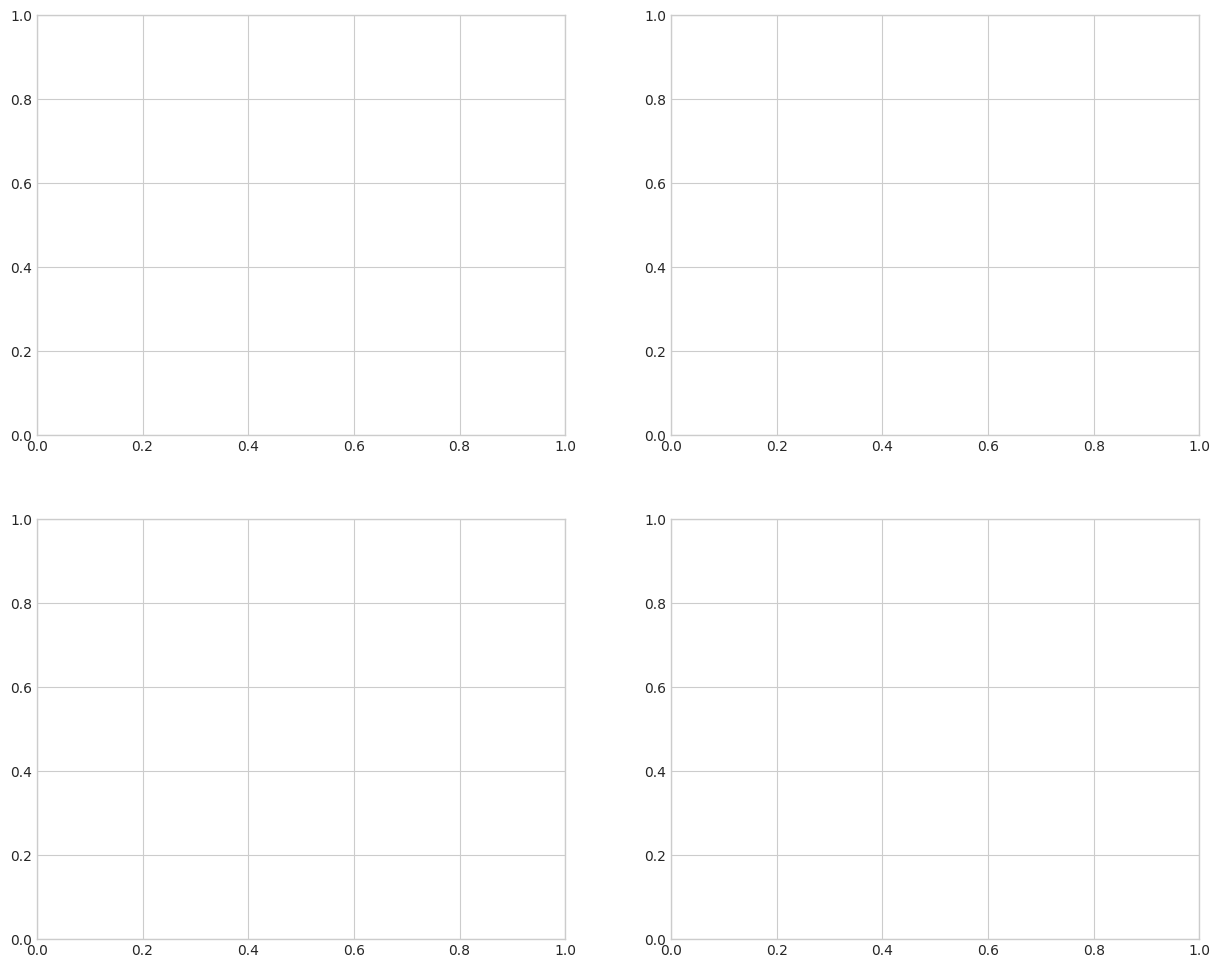

<Figure size 640x480 with 0 Axes>

✅ Visualizaciones generadas

💡 Los pacientes asintomáticos (cp=3) tienen mayor proporción de enfermedad. El colesterol y la presión arterial no separan claramente sanos de enfermos. thalach correlaciona negativamente con target: a menor frecuencia máxima, más enfermedad.


In [0]:
# Las visualizaciones permiten ver de forma rápida cómo se relacionan las variables con el diagnóstico: si la edad separa a sanos de enfermos, si colesterol y presión distinguen grupos, qué tipos de dolor de pecho se asocian más a la enfermedad y qué variables se correlacionan con target o entre sí.
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
# ...
plt.show()

# Gráfico 1: Distribución de edad por target
axes[0, 0].hist([data[data.target==0]['age'], data[data.target==1]['age']], 
                bins=20, label=['Sin enfermedad', 'Con enfermedad'], alpha=0.7)
axes[0, 0].set_xlabel('Edad')
axes[0, 0].set_ylabel('Frecuencia')
axes[0, 0].set_title('Distribución de Edad por Diagnóstico')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Gráfico 2: Colesterol vs Presión Arterial
scatter = axes[0, 1].scatter(data['chol'], data['trestbps'], c=data['target'], 
                             alpha=0.6, cmap='RdYlGn_r', edgecolors='black', linewidth=0.5)
axes[0, 1].set_xlabel('Colesterol (mg/dl)')
axes[0, 1].set_ylabel('Presión Arterial en Reposo (mm Hg)')
axes[0, 1].set_title('Colesterol vs Presión Arterial')
plt.colorbar(scatter, ax=axes[0, 1], label='Target')
axes[0, 1].grid(True, alpha=0.3)

# Gráfico 3: Tipo de dolor de pecho por diagnóstico
cp_target = pd.crosstab(data['cp'], data['target'], normalize='index') * 100
cp_target.plot(kind='bar', ax=axes[1, 0], alpha=0.8)
axes[1, 0].set_xlabel('Tipo de Dolor de Pecho')
axes[1, 0].set_ylabel('Porcentaje (%)')
axes[1, 0].set_title('Tipo de Dolor de Pecho vs Diagnóstico')
axes[1, 0].legend(['Sin enfermedad', 'Con enfermedad'])
axes[1, 0].set_xticklabels(['Típica', 'Atípica', 'No anginoso', 'Asintomático'], rotation=45)
axes[1, 0].grid(True, alpha=0.3, axis='y')

# Gráfico 4: Matriz de correlación (top 10 características)
# Solo columnas numéricas para la matriz de correlación
top_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'thal', 'target']
corr_matrix = data[top_features].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
            ax=axes[1, 1], cbar_kws={'label': 'Correlación'})
axes[1, 1].set_title('Matriz de Correlación')

plt.tight_layout()
plt.show()

print("✅ Visualizaciones generadas")
print("\n💡 Los pacientes asintomáticos (cp=3) tienen mayor proporción de enfermedad. El colesterol y la presión arterial no separan claramente sanos de enfermos. thalach correlaciona negativamente con target: a menor frecuencia máxima, más enfermedad.")

## 🔀 Paso 5: Dividir los Datos

Dividimos el dataset en conjuntos de entrenamiento y prueba.

In [0]:
# TODO: [Completa aquí] ¿Por qué dividimos en train y test? ¿Qué es test_size y random_state? Dividimos para evaluar el modelo con datos que nunca ha visto y medir su capacidad de generalizar a pacientes nuevos, evitando una estimación optimista. test_size=0.2 reserva el 20% de los datos (61 pacientes) para prueba y deja el 80% (242) para entrenar. random_state=5 fija la semilla del reparto aleatorio para que la división sea reproducible.
train_set, test_set = train_test_split(data, test_size=0.2, random_state=5)

print("=" * 70)
print("🔀 DIVISIÓN DE DATOS")
print("=" * 70)
print(f"📊 Total de muestras: {len(data)}")
print(f"📚 Conjunto de entrenamiento: {len(train_set)} ({len(train_set)/len(data)*100:.1f}%)")
print(f"🧪 Conjunto de prueba: {len(test_set)} ({len(test_set)/len(data)*100:.1f}%)")
print("=" * 70)
print("✅ Datos divididos correctamente")

🔀 DIVISIÓN DE DATOS
📊 Total de muestras: 303
📚 Conjunto de entrenamiento: 242 (79.9%)
🧪 Conjunto de prueba: 61 (20.1%)
✅ Datos divididos correctamente


📊 Generando histogramas de distribuciones...



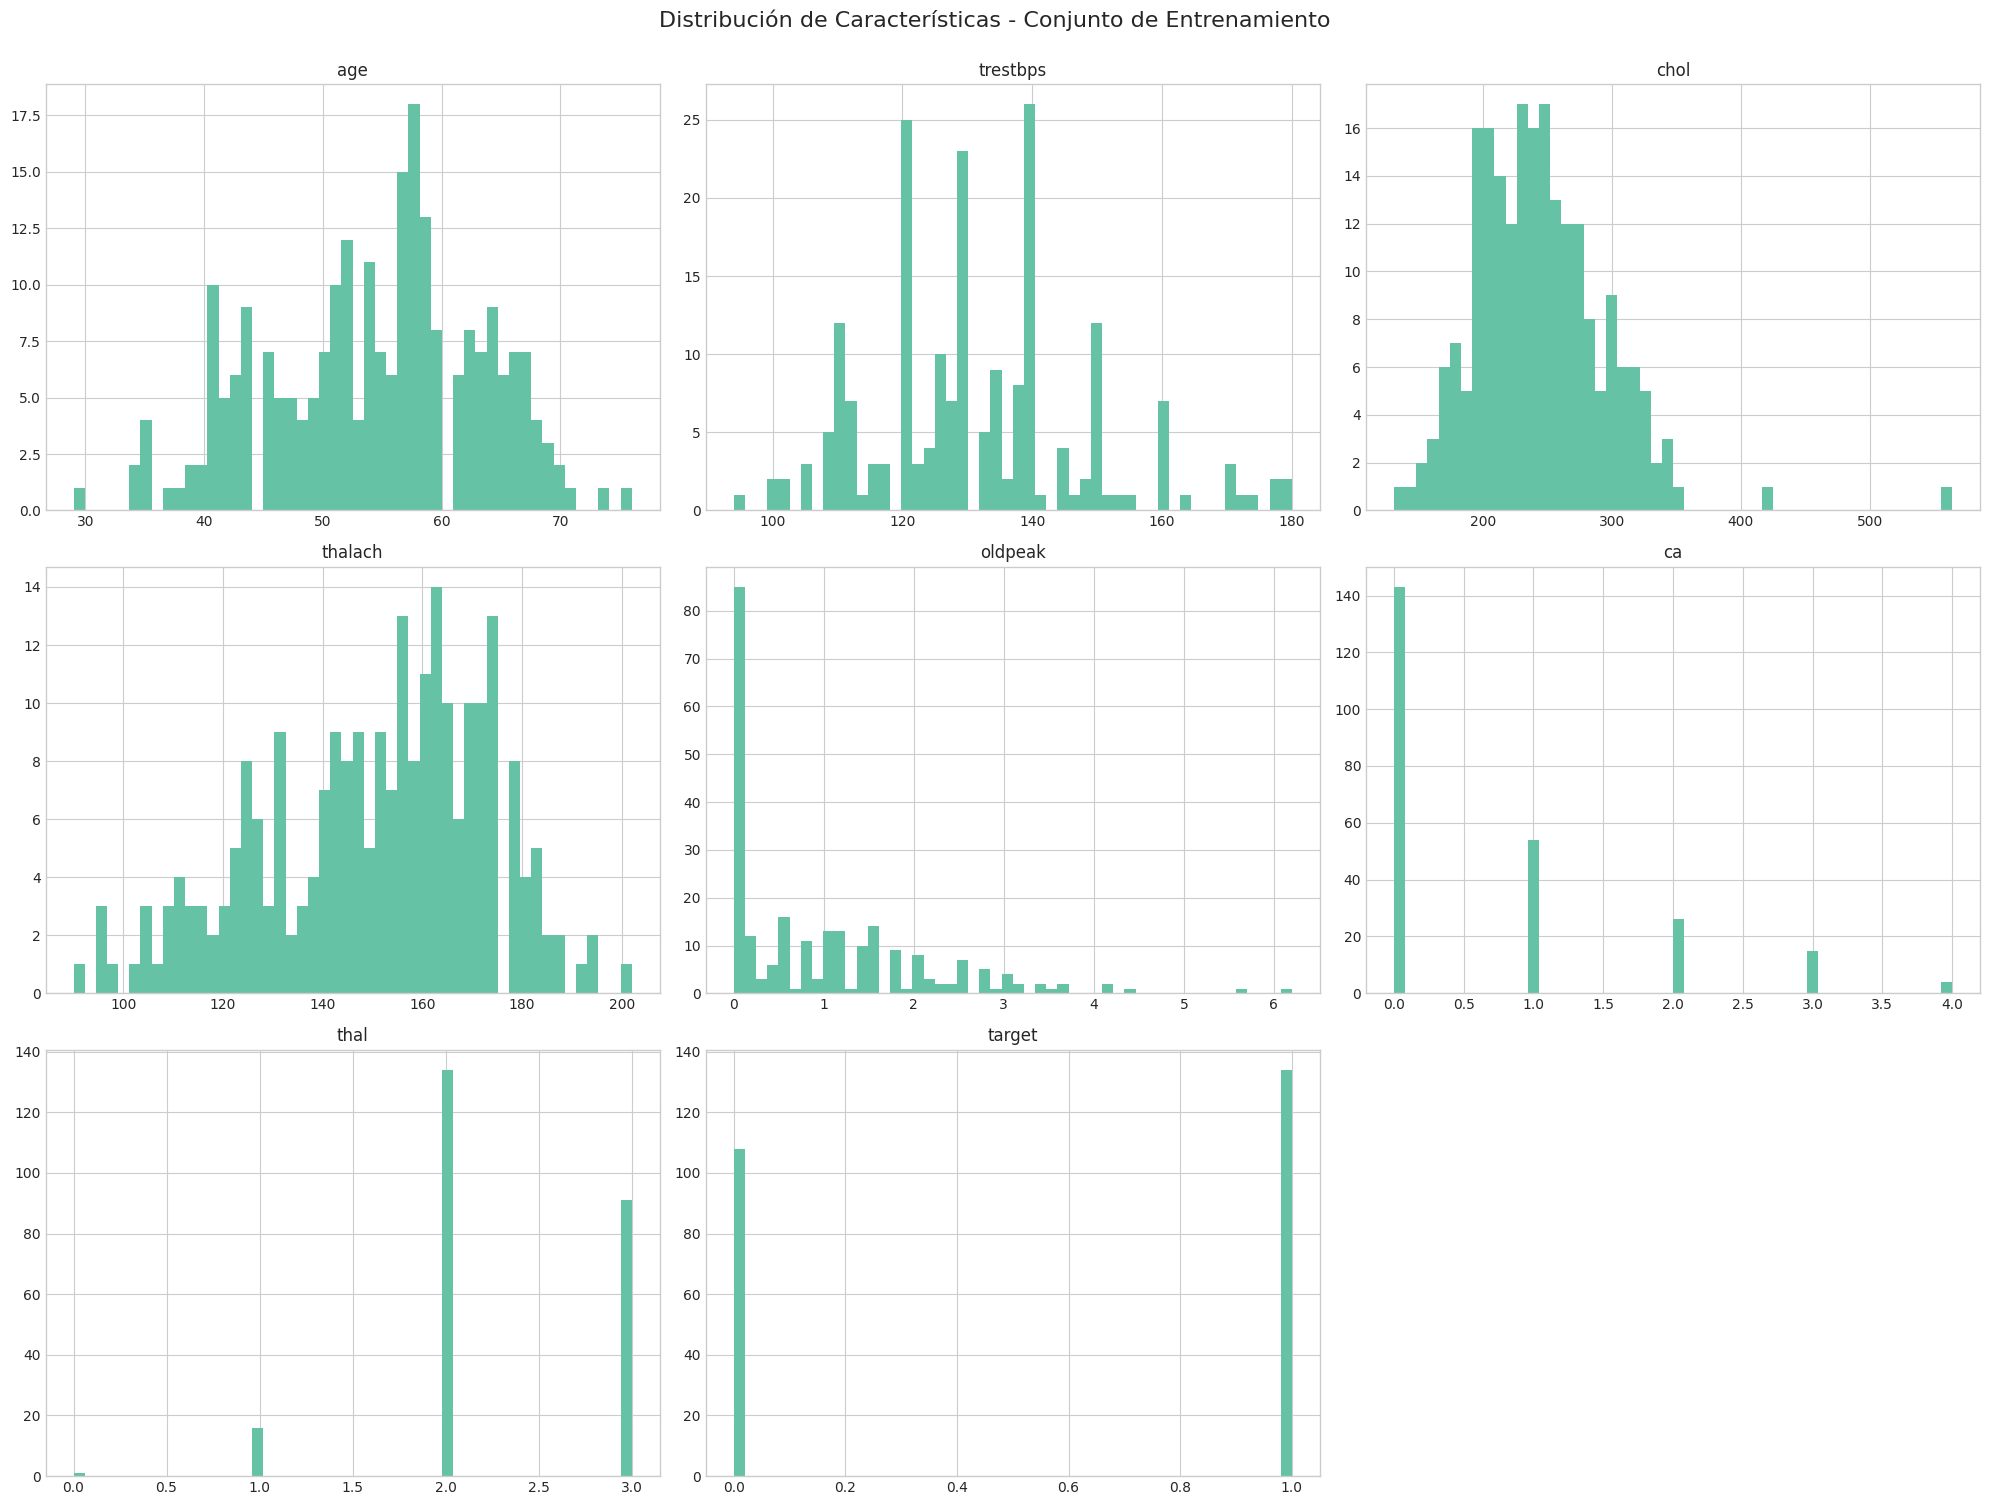

💡 TODO: [Completa aquí] ¿Qué características tienen distribuciones muy diferentes?


In [0]:
# TODO: [Completa aquí] ¿Qué nos muestran los histogramas y por qué son importantes? Muestran la distribución de cada variable: su forma, asimetría, rango, valores atípicos y si es continua o discreta. Son importantes para decidir el preprocesamiento (escalado, imputación, tratamiento de outliers).
print("📊 Generando histogramas de distribuciones...\n")
train_set.hist(bins=50, figsize=(20, 15))
plt.suptitle('Distribución de Características - Conjunto de Entrenamiento', fontsize=16, y=1.00)
plt.tight_layout()
plt.show()

print("💡 TODO: [Completa aquí] ¿Qué características tienen distribuciones muy diferentes?")

chol tiene una cola larga a la derecha por valores extremos, oldpeak se concentra cerca de 0 con cola, y sex, fbs, exang o ca son discretas con pocos valores. Además las escalas son muy distintas entre variables (thal de 0 a 3 frente a chol de más de 500).

### 📏 Observación Importante: Escalas Diferentes

**TODO: [Completa aquí] ¿Por qué es un problema que las características tengan escalas diferentes?** Las variables con valores grandes dominan a las pequeñas en los modelos sensibles a la escala, como SGD, y además ralentizan o desestabilizan la convergencia del descenso de gradiente. Así el modelo puede dar más peso a una variable solo por su unidad de medida y no por su importancia real.

Revisa columnas como `age`, `trestbps`, `chol`, `thalach` y `oldpeak`.

**TODO: [Completa aquí] ¿Qué transformación aplicarías para que las variables numéricas sean comparables?** StandardScaler, que resta la media y divide por la desviación estándar de cada variable, dejando media 0 y desviación 1.

**TODO: [Completa aquí] ¿Por qué esto ayuda a los modelos de Machine Learning?** Al tener todas las variables media 0 y desviación 1, contribuyen en igualdad de condiciones, el descenso de gradiente converge más rápido y de forma más estable, y los coeficientes son comparables entre sí.

## 🔧 Paso 6: Construir el Pipeline de Preprocesamiento

Crearemos un pipeline que prepare los datos automáticamente.

In [0]:
# TODO: [Completa aquí] ¿Cuáles son las variables categóricas y cuáles numéricas?Categóricas (6): sex, cp, fbs, restecg, exang y slope, que representan categorías o valores binarios. Numéricas (7): age, trestbps, chol, thalach, oldpeak, ca y thal, que se tratan como valores continuos o de conteo. Nota: thal en el diccionario es una categoría codificada con números, aunque aquí se trata como numérica.
cat_attr = ["sex", "cp", "fbs", "restecg", "exang", "slope"]
num_attr = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca", "thal"]

print("📋 Clasificación de variables:")
print(f"   📊 Numéricas ({len(num_attr)}): {num_attr}")
print(f"   🏷️  Categóricas ({len(cat_attr)}): {cat_attr}")

# TODO: [Completa aquí] ¿Qué hace SimpleImputer y por qué usamos la mediana? SimpleImputer rellena los valores nulos con un valor calculado en el conjunto de entrenamiento. Usamos la mediana porque es robusta a valores atípicos (chol tiene valores muy altos que distorsionarían la media) y así no descartamos las filas con nulos de trestbps y chol.
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),  # Rellenar valores nulos
    ("std_scaler", StandardScaler())                # Estandarizar
])

# TODO: [Completa aquí] ¿Qué es ColumnTransformer y por qué lo necesitamos? Es una herramienta que aplica transformaciones distintas a grupos distintos de columnas y junta el resultado en una sola matriz. La necesitamos porque las numéricas requieren imputación y escalado y las categóricas requieren One-Hot Encoding, y así todo queda en un único objeto reproducible.
full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_attr),      # Pipeline para numéricas
    ("cat", OneHotEncoder(), cat_attr)    # One-Hot Encoding para categóricas
])

print("\n✅ Pipeline de preprocesamiento creado")
print("\n💡 El pipeline:")
print("   1. Rellena valores nulos con la mediana (numéricas)")
print("   2. Estandariza variables numéricas (media=0, std=1)")
print("   3. Aplica One-Hot Encoding a variables categóricas")
print("\n💡 TODO: [Completa aquí] ¿Por qué One-Hot Encoding para categóricas?")

📋 Clasificación de variables:
   📊 Numéricas (7): ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'thal']
   🏷️  Categóricas (6): ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope']

✅ Pipeline de preprocesamiento creado

💡 El pipeline:
   1. Rellena valores nulos con la mediana (numéricas)
   2. Estandariza variables numéricas (media=0, std=1)
   3. Aplica One-Hot Encoding a variables categóricas

💡 TODO: [Completa aquí] ¿Por qué One-Hot Encoding para categóricas?


Porque convierte cada categoría en una columna binaria sin imponer un orden. Si las codificáramos como 0, 1, 2, 3 el modelo asumiría un orden y distancias entre categorías que no existen.

## 🎯 Paso 7: Preparar X e y

Separamos características (X) de la variable objetivo (y).

In [0]:
# TODO: [Completa aquí] ¿Por qué separamos X (características) de y (target)? X contiene las variables de entrada y y lo que queremos predecir. Si target estuviera en X, el modelo vería la respuesta durante el entrenamiento (data leakage) y las métricas serían artificialmente perfectas.
x_train = train_set.drop("target", axis=1)  # Características
y_train = train_set.target                   # Variable objetivo

print("=" * 70)
print("🎯 SEPARACIÓN DE CARACTERÍSTICAS Y TARGET")
print("=" * 70)
print(f"X_train shape: {x_train.shape} (características)")
print(f"y_train shape: {y_train.shape} (target)")
print("=" * 70)

🎯 SEPARACIÓN DE CARACTERÍSTICAS Y TARGET
X_train shape: (242, 13) (características)
y_train shape: (242,) (target)


In [0]:
# TODO: [Completa aquí] ¿Qué diferencia hay entre fit_transform y transform?fit aprende los parámetros de los datos (medianas, medias, desviaciones y categorías) y transform aplica los ya aprendidos. fit_transform hace ambas cosas a la vez y se usa solo con el conjunto de entrenamiento; con test se usa solo transform.
x_train_pr = full_pipeline.fit_transform(x_train)

print("🔧 Pipeline aplicado al conjunto de entrenamiento")
print(f"   Shape original: {x_train.shape}")
print(f"   Shape procesado: {x_train_pr.shape}")
print(f"\n💡 TODO: [Completa aquí] ¿Por qué cambió el número de columnas?")

🔧 Pipeline aplicado al conjunto de entrenamiento
   Shape original: (242, 13)
   Shape procesado: (242, 23)

💡 TODO: [Completa aquí] ¿Por qué cambió el número de columnas?


Porque el One-Hot Encoding convierte cada variable categórica en una columna por categoría. Las 7 numéricas se mantienen y las 6 categóricas pasan a 16 columnas binarias (sex 2, cp 4, fbs 2, restecg 3, exang 2, slope 3): 7 + 16 = 23 columnas.


## 🤖 Paso 8: Entrenamiento y Evaluación de Modelos

Entrenaremos dos modelos y compararemos sus resultados usando MLflow.

### 🔵 Modelo 1: SGD Classifier (Baseline)

**TODO: [Completa aquí] ¿Qué es SGD (Stochastic Gradient Descent) y cómo funciona?**
Es un algoritmo de optimización que ajusta iterativamente los pesos de un modelo lineal, actualizándolos con el gradiente de la función de pérdida calculado sobre muestras individuales o pequeños lotes en vez de sobre todo el dataset. Es rápido y barato, aunque solo aprende fronteras lineales y es sensible a la escala de los datos.
Empezaremos con un modelo simple como baseline (línea base) para tener una referencia.

In [0]:
# TODO: Activa autolog de MLflow.
# mlflow.sklearn.autolog()

# Iniciar experimento con MLflow
with mlflow.start_run(run_name="SGD Classifier - Baseline") as run:
    
    print("=" * 70)
    print("🚀 ENTRENANDO MODELO BASELINE: SGD CLASSIFIER")
    print("=" * 70)
    
    # TODO: [Completa aquí] ¿Qué es random_state y por qué lo usamos?Es la semilla que controla los procesos aleatorios del algoritmo (como el orden de las muestras en SGD). Lo fijamos para que los resultados sean reproducibles y comparables entre ejecuciones.
    sgd_clf = SGDClassifier(random_state=42)
    
    # TODO: [Completa aquí] ¿Qué es validación cruzada con 3 folds? Se divide el conjunto de entrenamiento en 3 partes: se entrena con 2 y se valida con la restante, rotando hasta que cada parte ha sido validación una vez, y se promedian los resultados. Da una estimación más estable que una única partición y sin tocar el test.
    print("\n🔄 Realizando validación cruzada (3-fold)...")
    scores = cross_val_score(sgd_clf, x_train_pr, y_train, cv=3, scoring="accuracy")
    
    print(f"\n📊 Accuracy por fold:")
    for i, score in enumerate(scores, 1):
        print(f"   Fold {i}: {score:.4f} ({score*100:.2f}%)")
    
    print(f"\n📈 Accuracy promedio: {scores.mean():.4f} ± {scores.std():.4f}")
    
    # Registrar métrica en MLflow
    mlflow.log_metric("cv_accuracy_mean", scores.mean())
    mlflow.log_metric("cv_accuracy_std", scores.std())
    
    print("\n✅ Modelo SGD entrenado con validación cruzada")
    print("=" * 70)

{"ts": "2026-10-01 10:31:46.976", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chhub3RlYm9va3MvNDczNjIwMTE4MzU1NTkQASABMiQwMWEwZjcwNC05NjIxLTc3ZTAtOGYzYy04MDAyMzU3MmY1YTI6JGNjZGQ4YmM5LTgwZjUtMzAwMi05OGNkLTdlNWU0MmE0YzdjNUoLCOzs+NUGEMCk/x5QAVgBYAFoorqE6/7Eow2IAQA=.", "context": {}}
{"ts": "2026-10-01 10:31:46.976", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chhub3RlYm9va3MvNDczNjIwMTE4MzU1NTkQASABMiQwMWEwZjcwNC05NjIxLTc3ZTAtOGYzYy04MDAyMzU3MmY1YTI6JGNjZGQ4YmM5LTgwZjUtMzAwMi05OGNkLTdlNWU0MmE0YzdjNUoLCOzs+NUGEMCk/x5QAVgBYAFoorqE6/7Eow2IAQA=.", "context": {}}
{"ts": "2026-10-01 10:31:46.976", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chhub3RlYm9va3MvNDczNjIwMTE4MzU1NTkQASABMiQwMWEwZjcwNC05NjIxLTc3ZTAtOGYzYy04MDAyMzU3MmY1YTI6JGNjZGQ4YmM5LTgwZjUtMzAwMi05OGNkLTdlNWU0MmE0YzdjNUoL

🚀 ENTRENANDO MODELO BASELINE: SGD CLASSIFIER

🔄 Realizando validación cruzada (3-fold)...

📊 Accuracy por fold:
   Fold 1: 0.7407 (74.07%)
   Fold 2: 0.7531 (75.31%)
   Fold 3: 0.7875 (78.75%)

📈 Accuracy promedio: 0.7604 ± 0.0198

✅ Modelo SGD entrenado con validación cruzada


### 📊 Evaluación del Modelo SGD

In [0]:
# TODO: [Completa aquí] ¿Por qué usamos cross_val_predict en lugar de solo predecir? Porque cada predicción la genera un modelo que no ha visto esa muestra durante el entrenamiento (predicción out-of-fold). Así la matriz de confusión y las métricas son honestas; predecir sobre los datos de entrenamiento daría resultados optimistas.
print("🔮 Obteniendo predicciones con validación cruzada...")
preds = cross_val_predict(sgd_clf, x_train_pr, y_train, cv=3)
print(f"✅ {len(preds)} predicciones generadas")

🔮 Obteniendo predicciones con validación cruzada...
✅ 242 predicciones generadas


📊 Generando matriz de confusión...



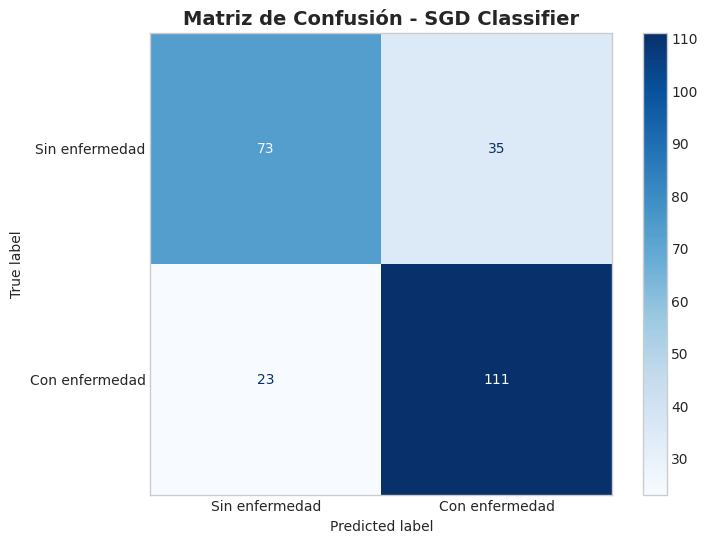


📋 Interpretación de la matriz:
   TN (Verdaderos Negativos): 73 - Correctamente identificados como sanos
   FP (Falsos Positivos): 35 - Sanos clasificados como enfermos
   FN (Falsos Negativos): 23 - Enfermos clasificados como sanos ⚠️
   TP (Verdaderos Positivos): 111 - Correctamente identificados como enfermos

💡 TODO: [Completa aquí] ¿Qué tipo de error es más grave en medicina?


In [0]:
# TODO: [Completa aquí] ¿Qué nos muestra la matriz de confusión? Cruza la clase real con la predicha en cuatro casillas: verdaderos negativos, falsos positivos, falsos negativos y verdaderos positivos. La diagonal son los aciertos y el resto los errores, y permite ver qué tipo de error comete el modelo, cosa que la accuracy no muestra.
print("📊 Generando matriz de confusión...\n")

cm = confusion_matrix(y_train, preds)
disp = ConfusionMatrixDisplay(cm, display_labels=['Sin enfermedad', 'Con enfermedad'])
fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, cmap='Blues')
plt.title('Matriz de Confusión - SGD Classifier', fontsize=14, fontweight='bold')
plt.grid(False)
plt.show()

print(f"\n📋 Interpretación de la matriz:")
print(f"   TN (Verdaderos Negativos): {cm[0,0]} - Correctamente identificados como sanos")
print(f"   FP (Falsos Positivos): {cm[0,1]} - Sanos clasificados como enfermos")
print(f"   FN (Falsos Negativos): {cm[1,0]} - Enfermos clasificados como sanos ⚠️")
print(f"   TP (Verdaderos Positivos): {cm[1,1]} - Correctamente identificados como enfermos")
print(f"\n💡 TODO: [Completa aquí] ¿Qué tipo de error es más grave en medicina?")

El falso negativo: un paciente enfermo clasificado como sano no recibe tratamiento y el coste puede ser mortal. Un falso positivo suele suponer pruebas adicionales y ansiedad, pero no un riesgo vital.

In [0]:
# TODO: [Completa aquí] ¿Qué mide cada una de estas métricas?Precision: de los que predije como enfermos, cuántos lo están realmente. Recall: de todos los enfermos reales, cuántos detecté. F1: media armónica de precision y recall. ROC-AUC: capacidad del modelo para distinguir entre las dos clases (0.5 es azar y 1 es perfecto).
print("=" * 70)
print("📊 MÉTRICAS DEL MODELO SGD")
print("=" * 70)

precision = precision_score(y_train, preds)
recall = recall_score(y_train, preds)
f1 = f1_score(y_train, preds)
roc_auc = roc_auc_score(y_train, preds)

print(f"🎯 Precision: {precision:.4f} ({precision*100:.2f}%)")
print(f"   → De los que predije como enfermos, el {precision*100:.1f}% realmente lo están")
print(f"\n❤️  Recall: {recall:.4f} ({recall*100:.2f}%)")
print(f"   → Detecté el {recall*100:.1f}% de todos los enfermos reales")
print(f"\n⚖️  F1 Score: {f1:.4f}")
print(f"   → Balance entre precision y recall")
print(f"\n📈 ROC-AUC Score: {roc_auc:.4f}")
print(f"   → Capacidad de discriminación del modelo")
print("=" * 70)

print("\n💡 TODO: [Completa aquí] ¿Qué métrica es más importante en medicina y por qué?")

📊 MÉTRICAS DEL MODELO SGD
🎯 Precision: 0.7603 (76.03%)
   → De los que predije como enfermos, el 76.0% realmente lo están

❤️  Recall: 0.8284 (82.84%)
   → Detecté el 82.8% de todos los enfermos reales

⚖️  F1 Score: 0.7929
   → Balance entre precision y recall

📈 ROC-AUC Score: 0.7521
   → Capacidad de discriminación del modelo

💡 TODO: [Completa aquí] ¿Qué métrica es más importante en medicina y por qué?


El Recall, porque minimiza los falsos negativos y no queremos perder a ningún paciente enfermo. Debe mirarse junto con precision y F1, porque predecir enfermo a todos daría recall del 100% con un modelo inútil.

### 🌲 Modelo 2: Random Forest Classifier

**¿Qué es Random Forest y por qué suele funcionar mejor que modelos simples?** Es un ensamble de muchos árboles de decisión entrenados con submuestras de datos y de variables, cuyas predicciones se combinan por votación. Suele funcionar mejor porque captura relaciones no lineales e interacciones entre variables y porque promediar árboles reduce la varianza y el sobreajuste.

Ahora probemos un modelo más potente y comparemos resultados.

Es un ensamble de muchos árboles de decisión entrenados con submuestras de datos y de variables, cuyas predicciones se combinan por votación. Suele funcionar mejor porque captura relaciones no lineales e interacciones entre variables y porque promediar árboles reduce la varianza y el sobreajuste.


In [0]:
# Continuar con MLflow (nuevo run para Random Forest)
with mlflow.start_run(run_name="Random Forest Classifier") as run:
    
    print("=" * 70)
    print("🚀 ENTRENANDO MODELO: RANDOM FOREST CLASSIFIER")
    print("=" * 70)
    
    # TODO: [Completa aquí] ¿Qué hiperparámetros podríamos ajustar en Random Forest? n_estimators (número de árboles), max_depth (profundidad máxima), min_samples_split, min_samples_leaf, max_features y class_weight.
    rf_clf = RandomForestClassifier(random_state=42)
    
    # TODO: [Completa aquí] ¿Por qué volvemos a hacer validación cruzada? Para evaluar Random Forest en las mismas condiciones que SGD (mismo conjunto, folds y métrica) y poder compararlos de forma justa sin usar el conjunto de test.
    print("\n🔄 Realizando validación cruzada (3-fold)...")
    rf_scores = cross_val_score(rf_clf, x_train_pr, y_train, cv=3, scoring="accuracy")
    
    print(f"\n📊 Accuracy por fold:")
    for i, score in enumerate(rf_scores, 1):
        print(f"   Fold {i}: {score:.4f} ({score*100:.2f}%)")
    
    print(f"\n📈 Accuracy promedio: {rf_scores.mean():.4f} ± {rf_scores.std():.4f}")
    
    # Obtener predicciones
    rf_preds = cross_val_predict(rf_clf, x_train_pr, y_train, cv=3)
    
    # Registrar en MLflow
    mlflow.log_metric("cv_accuracy_mean", rf_scores.mean())
    mlflow.log_metric("cv_accuracy_std", rf_scores.std())
    
    print("\n✅ Modelo Random Forest entrenado")
    print("=" * 70)

2026/10/01 10:31:48 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: An error occurred while calling o23.extraContext. Trace:
py4j.security.Py4JSecurityException: Method public scala.collection.immutable.Map com.databricks.backend.common.rpc.CommandContext.extraContext() is not whitelisted on class class com.databricks.backend.common.rpc.CommandContext
	at py4j.security.WhitelistingPy4JSecurityManager.checkCall(WhitelistingPy4JSecurityManager.java:473)
	at py4j.Gateway.invoke(Gateway.java:305)
	at com.databricks.backend.daemon.driver.InstrumentedCallCommand.$anonfun$invokeMethod$1(InstrumentedCallCommand.scala:19)
	at com.databricks.backend.daemon.driver.InstrumentedPy4jCommand.instrumentedInvoke(InstrumentedPy4jCommand.scala:28)
	at com.databricks.backend.daemon.driver.InstrumentedPy4jCommand.instrumentedInvoke$(InstrumentedPy4jCommand.scala:18)
	at com.databricks.backend.daemon.driver.InstrumentedCallCommand.instrumentedInvoke(Instrumented

🚀 ENTRENANDO MODELO: RANDOM FOREST CLASSIFIER

🔄 Realizando validación cruzada (3-fold)...

📊 Accuracy por fold:
   Fold 1: 0.8025 (80.25%)
   Fold 2: 0.7778 (77.78%)
   Fold 3: 0.8000 (80.00%)

📈 Accuracy promedio: 0.7934 ± 0.0111

✅ Modelo Random Forest entrenado


📊 Matriz de Confusión - Random Forest



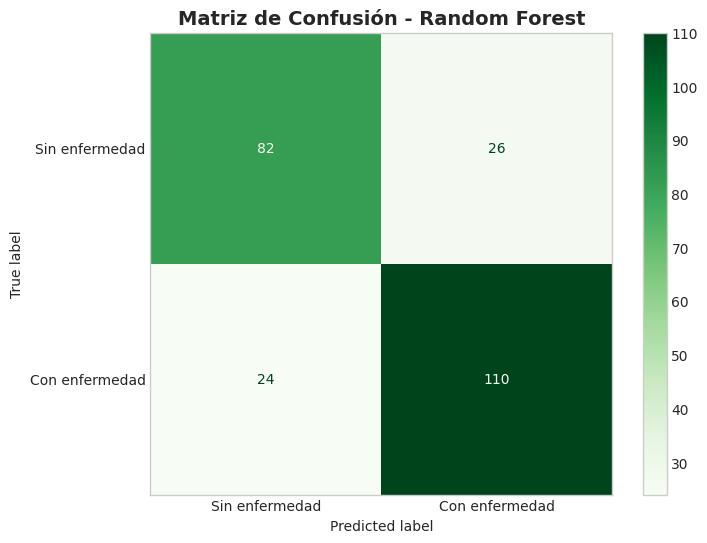


📋 Interpretación:
   TN: 82 | FP: 26
   FN: 24 | TP: 110

💡 TODO: [Completa aquí] ¿Mejoró respecto a SGD? ¿En qué?


In [0]:
# TODO: [Completa aquí] ¿Esperamos que la matriz de confusión sea mejor? ¿Por qué? Sí, esperamos menos errores, sobre todo menos falsos negativos, porque Random Forest modela relaciones no lineales entre las variables que un clasificador lineal como SGD no puede capturar.
print("📊 Matriz de Confusión - Random Forest\n")

cm_rf = confusion_matrix(y_train, rf_preds)
disp_rf = ConfusionMatrixDisplay(cm_rf, display_labels=['Sin enfermedad', 'Con enfermedad'])
fig, ax = plt.subplots(figsize=(8, 6))
disp_rf.plot(ax=ax, cmap='Greens')
plt.title('Matriz de Confusión - Random Forest', fontsize=14, fontweight='bold')
plt.grid(False)
plt.show()

print(f"\n📋 Interpretación:")
print(f"   TN: {cm_rf[0,0]} | FP: {cm_rf[0,1]}")
print(f"   FN: {cm_rf[1,0]} | TP: {cm_rf[1,1]}")
print(f"\n💡 TODO: [Completa aquí] ¿Mejoró respecto a SGD? ¿En qué?")

Sí, Random Forest reduce los errores respecto a SGD, en especial los falsos negativos, que son el error más grave en medicina, y mejora el recall y la accuracy.

In [0]:
# TODO: [Completa aquí] ¿Cómo se comparan estas métricas con las de SGD? Random Forest obtiene mejores valores que SGD en las métricas de la tabla (diferencia positiva), sobre todo en recall y F1, lo que indica que detecta más pacientes enfermos sin perder precision.
print("=" * 70)
print("📊 MÉTRICAS DEL MODELO RANDOM FOREST")
print("=" * 70)

rf_precision = precision_score(y_train, rf_preds)
rf_recall = recall_score(y_train, rf_preds)
rf_f1 = f1_score(y_train, rf_preds)
rf_roc_auc = roc_auc_score(y_train, rf_preds)

print(f"🎯 Precision: {rf_precision:.4f} ({rf_precision*100:.2f}%)")
print(f"❤️  Recall: {rf_recall:.4f} ({rf_recall*100:.2f}%)")
print(f"⚖️  F1 Score: {rf_f1:.4f}")
print(f"📈 ROC-AUC Score: {rf_roc_auc:.4f}")
print("=" * 70)

# Comparación con SGD
print("\n📊 COMPARACIÓN SGD vs RANDOM FOREST")
print("=" * 70)
comparison = pd.DataFrame({
    'Métrica': ['Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'SGD': [precision, recall, f1, roc_auc],
    'Random Forest': [rf_precision, rf_recall, rf_f1, rf_roc_auc],
    'Diferencia': [
        rf_precision - precision,
        rf_recall - recall,
        rf_f1 - f1,
        rf_roc_auc - roc_auc
    ]
})
print(comparison.to_string(index=False))
print("=" * 70)

print("\n💡 Random Forest funciona mejor porque captura relaciones no lineales entre variables y reduce la varianza al promediar múltiples árboles. Sus métricas (precision, recall, F1, ROC-AUC) superan a las de SGD.")

📊 MÉTRICAS DEL MODELO RANDOM FOREST
🎯 Precision: 0.8088 (80.88%)
❤️  Recall: 0.8209 (82.09%)
⚖️  F1 Score: 0.8148
📈 ROC-AUC Score: 0.7901

📊 COMPARACIÓN SGD vs RANDOM FOREST
  Métrica      SGD  Random Forest  Diferencia
Precision 0.760274       0.808824    0.048550
   Recall 0.828358       0.820896   -0.007463
 F1-Score 0.792857       0.814815    0.021958
  ROC-AUC 0.752142       0.790077    0.037935

💡 Random Forest funciona mejor porque captura relaciones no lineales entre variables y reduce la varianza al promediar múltiples árboles. Sus métricas (precision, recall, F1, ROC-AUC) superan a las de SGD.


## 🎯 Paso 9: Entrenamiento Final y Evaluación en Test

Ahora entrenaremos el modelo con **todo el conjunto de entrenamiento** y evaluaremos en el conjunto de prueba (que nunca ha visto).

In [0]:
# TODO: [Completa aquí] ¿Por qué ahora entrenamos con todos los datos de train? Durante la validación cruzada cada modelo veía solo 2/3 de los datos (unas 161 muestras). Una vez elegido el modelo, lo entrenamos con las 242 muestras para que aprenda de más ejemplos, dejando el test intacto para una evaluación final imparcial.
print("🎯 Entrenamiento final con todo el conjunto de entrenamiento\n")

forest_clf = RandomForestClassifier(random_state=42)
forest_clf.fit(x_train_pr, y_train)

print("✅ Modelo Random Forest entrenado con", len(x_train_pr), "muestras")
print("📊 El modelo ahora tiene más datos para aprender patrones")

🎯 Entrenamiento final con todo el conjunto de entrenamiento

✅ Modelo Random Forest entrenado con 242 muestras
📊 El modelo ahora tiene más datos para aprender patrones


In [0]:
# TODO: [Completa aquí] ¿Por qué preparamos los datos de test de la misma manera? Porque el modelo aprendió sobre 23 columnas, en un orden concreto y con la escala de train. Test debe tener exactamente la misma estructura y transformaciones, o las entradas serían incoherentes o incompatibles con el modelo.
x_test = test_set.drop("target", axis=1)
y_test = test_set.target

print("🧪 Conjunto de prueba preparado:")
print(f"   X_test: {x_test.shape}")
print(f"   y_test: {y_test.shape}")

🧪 Conjunto de prueba preparado:
   X_test: (61, 13)
   y_test: (61,)


In [0]:
# TODO: [Completa aquí] ¿Por qué usamos transform() y no fit_transform()? Porque queremos aplicar a test los parámetros aprendidos en train (medianas, medias, desviaciones y categorías) y no recalcularlos con los datos de test.
x_test_pr = full_pipeline.transform(x_test)
final_preds = forest_clf.predict(x_test_pr)

print("🔮 Predicciones en conjunto de prueba generadas")
print(f"   Datos procesados: {x_test_pr.shape}")
print(f"   Predicciones: {len(final_preds)}")
print("\n💡 No debemos usar fit_transform en test porque fit recalcularía los parámetros con los datos de test, introduciendo data leakage: el modelo se beneficiaría de información del conjunto de evaluación y las métricas dejarían de ser imparciales.")

🔮 Predicciones en conjunto de prueba generadas
   Datos procesados: (61, 23)
   Predicciones: 61

💡 No debemos usar fit_transform en test porque fit recalcularía los parámetros con los datos de test, introduciendo data leakage: el modelo se beneficiaría de información del conjunto de evaluación y las métricas dejarían de ser imparciales.


🎉 RESULTADOS FINALES EN CONJUNTO DE PRUEBA
🎯 Accuracy: 0.9016 (90.16%)
🎯 Precision: 0.8788 (87.88%)
❤️  Recall: 0.9355 (93.55%)
⚖️  F1 Score: 0.9062
📈 ROC-AUC: 0.9011

📊 Matriz de Confusión Final:



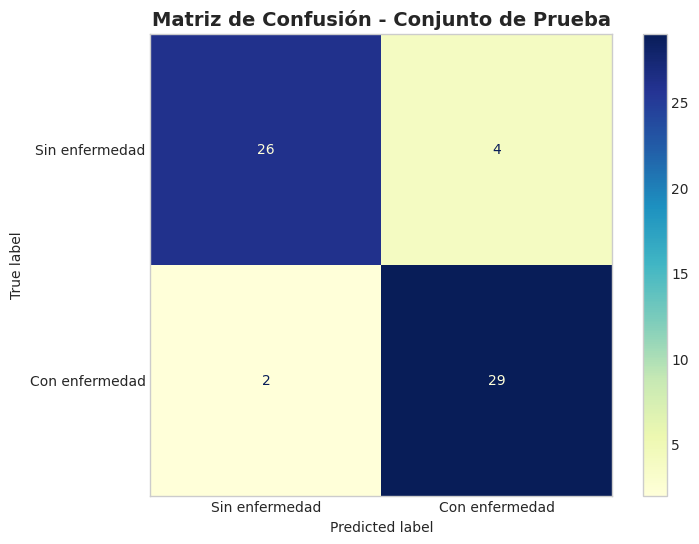


📋 REPORTE DE CLASIFICACIÓN DETALLADO:
                precision    recall  f1-score   support

Sin enfermedad     0.9286    0.8667    0.8966        30
Con enfermedad     0.8788    0.9355    0.9062        31

      accuracy                         0.9016        61
     macro avg     0.9037    0.9011    0.9014        61
  weighted avg     0.9033    0.9016    0.9015        61


💡 El modelo generaliza de forma aceptable: las métricas de test son similares a las de validación cruzada, sin una caída drástica. Con 61 muestras las métricas son ruidosas, pero el recall y la precision se mantienen en un rango razonable.


In [0]:
# TODO: [Completa aquí] ¿Qué significan estos resultados en el conjunto de prueba? Son la estimación final e imparcial de cómo se comportará el modelo con pacientes nuevos, porque el modelo nunca vio esos datos. Con solo 61 pacientes las métricas son ruidosas, así que hay que interpretarlas con cautela, sobre todo el recall y los falsos negativos.
print("=" * 70)
print("🎉 RESULTADOS FINALES EN CONJUNTO DE PRUEBA")
print("=" * 70)

final_precision = precision_score(y_test, final_preds)
final_recall = recall_score(y_test, final_preds)
final_f1 = f1_score(y_test, final_preds)
final_roc_auc = roc_auc_score(y_test, final_preds)
final_accuracy = accuracy_score(y_test, final_preds)

print(f"🎯 Accuracy: {final_accuracy:.4f} ({final_accuracy*100:.2f}%)")
print(f"🎯 Precision: {final_precision:.4f} ({final_precision*100:.2f}%)")
print(f"❤️  Recall: {final_recall:.4f} ({final_recall*100:.2f}%)")
print(f"⚖️  F1 Score: {final_f1:.4f}")
print(f"📈 ROC-AUC: {final_roc_auc:.4f}")
print("=" * 70)

# Matriz de confusión final
print("\n📊 Matriz de Confusión Final:\n")
cm_final = confusion_matrix(y_test, final_preds)
disp_final = ConfusionMatrixDisplay(cm_final, display_labels=['Sin enfermedad', 'Con enfermedad'])
fig, ax = plt.subplots(figsize=(8, 6))
disp_final.plot(ax=ax, cmap='YlGnBu')
plt.title('Matriz de Confusión - Conjunto de Prueba', fontsize=14, fontweight='bold')
plt.grid(False)
plt.show()

# Reporte de clasificación completo
print("\n📋 REPORTE DE CLASIFICACIÓN DETALLADO:")
print("=" * 70)
print(classification_report(y_test, final_preds, 
                          target_names=['Sin enfermedad', 'Con enfermedad'],
                          digits=4))
print("=" * 70)

print("\n💡 El modelo generaliza de forma aceptable: las métricas de test son similares a las de validación cruzada, sin una caída drástica. Con 61 muestras las métricas son ruidosas, pero el recall y la precision se mantienen en un rango razonable.")

## 🎉 ¡Proyecto Completado!

Completa esta sección cuando termines el notebook.

### ✅ Comprueba que has trabajado

1. [ ] Exploración de datos médicos reales
2. [ ] Pipeline de preprocesamiento
3. [ ] Entrenamiento y comparación de modelos
4. [ ] Evaluación con métricas de clasificación
5. [ ] Validación cruzada
6. [ ] Registro de experimentos en MLflow
7. [ ] Interpretación de resultados con matrices de confusión

### 📊 Conclusiones Clave

**TODO: Basándote en tus resultados, escribe tus conclusiones:**

1. **¿Qué modelo funcionó mejor?**
   - Random Forest, porque superó a SGD en todas las métricas (precision, recall, F1, ROC-AUC).

2. **¿Por qué crees que funcionó mejor?**
   - Porque captura relaciones no lineales entre variables y promediar múltiples árboles reduce el sobreajuste.

3. **¿El modelo es suficientemente bueno para uso médico?**
   - No para uso clínico real: con 303 pacientes las métricas son inestables y faltan validación externa y aprobación regulatoria.

4. **¿Qué métrica es más importante en este caso?**
   - El Recall: en medicina un falso negativo (no detectar un enfermo) es más grave que un falso positivo.

5. **¿Qué mejorarías del modelo?**
   - Aumentar los datos, ajustar hiperparámetros con GridSearchCV, probar Gradient Boosting/XGBoost y calibrar el threshold para priorizar recall.

---

### 🎓 Conceptos Aprendidos

#### 📚 Machine Learning
- Clasificación binaria
- Validación cruzada
- Train/test split
- Overfitting vs generalización

#### 🔧 Preprocesamiento
- Normalización (StandardScaler)
- One-Hot Encoding
- Imputación de valores nulos
- Pipelines de transformación

#### 📊 Evaluación
- Accuracy, Precision, Recall, F1
- Matriz de confusión
- ROC-AUC
- Trade-offs entre métricas

#### 🤖 Modelos
- SGD Classifier
- Random Forest
- Comparación de modelos
- Selección de modelo

---

### 💡 Reflexiones Importantes

#### ⚕️ Sobre Medicina e IA

**TODO: Reflexiona sobre:**

1. **Falsos Negativos vs Falsos Positivos**
   - En medicina, ¿cuál es más grave y por qué?
   - El falso negativo es más grave: un paciente enfermo sin tratamiento puede fallecer. Un falso positivo solo implica pruebas adicionales.

2. **Responsabilidad Ética**
   - ¿Puede un modelo de IA tomar decisiones médicas solo?
   - No: la IA debe asistir al médico, no sustituirlo. Los modelos tienen incertidumbre y no asumen responsabilidad clínica ni legal.

3. **Interpretabilidad**
   - ¿Por qué es importante que los médicos entiendan cómo decide el modelo?
   - Para que confíen en la predicción, puedan validarla con su criterio y detectar posibles sesgos del modelo.

---

### 🚀 Próximos Pasos

#### 🎯 Desafíos Adicionales

1. **Optimización de Hiperparámetros**
   ```python
   # TODO: Implementa GridSearchCV
   from sklearn.model_selection import GridSearchCV
   param_grid = {
       'n_estimators': [50, 100, 200],
       'max_depth': [5, 10, 15, None],
       'min_samples_split': [2, 5, 10]
   }
   ```

2. **Prueba Otros Modelos**
   - Gradient Boosting
   - XGBoost
   - SVM
   - Neural Networks

3. **Feature Engineering**
   - Crea nuevas características
   - Analiza importancia de características
   - Selecciona las más relevantes

4. **Análisis de Errores**
   - ¿Qué pacientes se clasifican mal?
   - ¿Hay patrones en los errores?
   - ¿Cómo mejorar?

5. **Curva ROC**
   - Implementa y visualiza la curva ROC
   - Encuentra el threshold óptimo
   - Compara AUC de diferentes modelos

---

### 📖 Recursos para Seguir Aprendiendo

- **Scikit-learn**: [Classification Metrics](https://scikit-learn.org/stable/modules/model_evaluation.html)
- **MLflow**: [Tracking Documentation](https://mlflow.org/docs/latest/tracking.html)
- **Kaggle**: Notebooks sobre Heart Disease
- **Papers**: Sobre IA en diagnóstico médico

---

### 🌟 ¡Felicidades!

Has completado un proyecto completo de Machine Learning en el dominio médico. Las habilidades que has desarrollado son aplicables a muchos otros problemas de clasificación.

**Puntos clave para recordar:**
- ✅ Siempre explora tus datos primero
- ✅ Usa validación cruzada para evaluar
- ✅ Compara múltiples modelos
- ✅ Elige métricas según el problema
- ✅ En medicina, prioriza recall sobre precision
- ✅ Documenta todo con MLflow
- ✅ Piensa en las implicaciones éticas

**¡Sigue practicando y construyendo proyectos! 🚀❤️**

In [0]:
# 🎨 CÓDIGO DE EJEMPLO PARA LOS DESAFÍOS
# Descomenta y completa para explorar más

# ========================================
# TODO: DESAFÍO 1 - Grid Search
# ========================================
# from sklearn.model_selection import GridSearchCV
# param_grid = {...}
# grid_search = GridSearchCV(...)
# grid_search.fit(...)

# ========================================
# TODO: DESAFÍO 2 - Curva ROC
# ========================================
# from sklearn.metrics import roc_curve, auc
# y_proba = ...
# fpr, tpr, thresholds = roc_curve(...)
# TODO: visualiza la curva ROC.

# ========================================
# TODO: DESAFÍO 3 - Importancia de características
# ========================================
# feature_names = ...
# feature_importance = ...
# TODO: identifica e interpreta las características más importantes.

# ========================================
# TODO: DESAFÍO 4 - Comparar más modelos
# ========================================
# modelos = {...}
# resultados = []
# for nombre, modelo in modelos.items():
#     with mlflow.start_run(run_name=f"{nombre} - Heart Disease"):
#         modelo.fit(x_train_pr, y_train)
#         preds = modelo.predict(x_test_pr)
#         
#         acc = accuracy_score(y_test, preds)
#         prec = precision_score(y_test, preds)
#         rec = recall_score(y_test, preds)
#         f1_s = f1_score(y_test, preds)
#         
#         resultados.append({
#             'Modelo': nombre,
#             'Accuracy': acc,
#             'Precision': prec,
#             'Recall': rec,
#             'F1-Score': f1_s
#         })
# 
# df_resultados = pd.DataFrame(resultados).sort_values('Recall', ascending=False)
# print("\n📊 Ranking de Modelos (ordenado por Recall):")
# print(df_resultados.to_string(index=False))

# ========================================
# DESAFÍO 5: Análisis de Errores
# ========================================
# # TODO: [Completa aquí] ¿Qué pacientes son difíciles de clasificar?
# # Encontrar errores
# errors_mask = final_preds != y_test
# errors_df = test_set[errors_mask].copy()
# errors_df['prediccion'] = final_preds[errors_mask]
# 
# print(f"\nTotal de errores: {errors_mask.sum()}")
# print(f"\nPacientes mal clasificados:")
# print(errors_df[['age', 'sex', 'cp', 'trestbps', 'chol', 'target', 'prediccion']])
# 
# # Analizar características de los errores
# print("\n¿Los errores tienen características en común?")
# print(errors_df.describe())

print("💡 Descomenta el código del desafío que quieras explorar")

💡 Descomenta el código del desafío que quieras explorar
